# 실습 9. EOF 분석: 복잡한 기후자료를 몇 개의 패턴으로 요약하기

## 오늘의 목표

1. 여러 시점의 지도를 **공간 패턴**(EOF)과 **시간 변화**(PC)로 요약하는 이유를 설명한다.
2. 공분산 행렬 → 고유벡터 → 투영(PC)의 관계를 작은 예제로 확인한다.
3. 열대 태평양 SST 편차를 이용해 EOF 분석을 수행하고, **패턴·PC·분산 설명률**을 읽는다.
4. 같은 절차를 겨울철 북태평양 해면기압(SLP)에 적용할 준비를 한다.

**진행 순서:** (참고) 이론 복습 → **★ 핵심 코드** SST 실습 (1~3) → (참고) 더 알아보기 → 과제

> **★ 핵심 코드** 표시가 있는 셀은 과제에 응용할 핵심 코드이다. `(참고)`는 결과를 이해하기 위한 보충 내용


In [1]:
# ★ 핵심 코드
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from eofs.xarray import Eof          # EOF 분석 패키지 (conda install -c conda-forge eofs)

## (참고) 이론 복습: EOF analysis

이론 강의의 핵심은 **차원 축소**이다. EOF는 자료의 변동을 가장 많이 설명하는 새로운 축을 찾고, 그 축에 자료를 투영한다. 첫 번째 축은 가장 큰 분산을, 다음 축은 앞선 축과 직교하면서 남은 분산 중 가장 큰 부분을 설명한다.

- **EOF:** 공간적으로 어떤 격자점들이 함께 변하는가? (공간 패턴)
- **PC:** 원래 자료를 EOF 축에 투영하여 얻은 값으로, 그 패턴이 시간에 따라 어떻게 나타나는가? (PC 시계열)
- **분산 설명률:** 전체 변동 중 각 모드가 차지하는 비율은 얼마인가?

**주의:** 직교한다는 것은 수학적 조건이다. 각 모드가 반드시 서로 독립적인 물리 현상을 뜻하지는 않는다. EOF와 PC의 부호는 함께 뒤집어도 같은 변동을 나타낸다. 

아래는 강의자료의 공분산 행렬 → 고유값·고유벡터 → 투영을 작은 숫자로 확인하는 **참고 실습**이다.

### Covariance matrix

시간마다 SST 지도가 한 장씩 있다. 각 지도를 **한 줄로 펼쳐 열벡터로 쌓으면** 자료 행렬 $X$가 된다.

- $X$: 행 = 격자점 ($m$개), 열 = 시간 ($N$개) → 크기 $m \times N$
- 공분산 행렬: $C = XX^T/(N-1)$ → 크기 $m \times m$

**공분산은 두 변수의 편차를 곱한 값의 평균으로, 두 변수가 함께 어떻게 변하는지를 나타낸다.**

따라서 $XX^T$를 계산하면 각 격자점 사이의 공분산을 구할 수 있다. 이때 대각 성분은 각 격자점의 분산이고, 나머지 성분은 서로 다른 격자점 사이의 공분산이다.

격자점 3개, 시간 4개짜리 작은 예로 확인해 보자.

In [2]:
X = np.array([[ 1, -1,  2, -2],     # 격자점 x1 의 anomaly (시간 4개)
              [ 1, -1,  1, -1],     # 격자점 x2
              [-1,  1,  0,  0]])    # 격자점 x3
m, N = X.shape                      # m = 3 (격자점), N = 4 (시간)

C = X @ X.T / (N-1)                 # 공분산 행렬 (3 x 3)

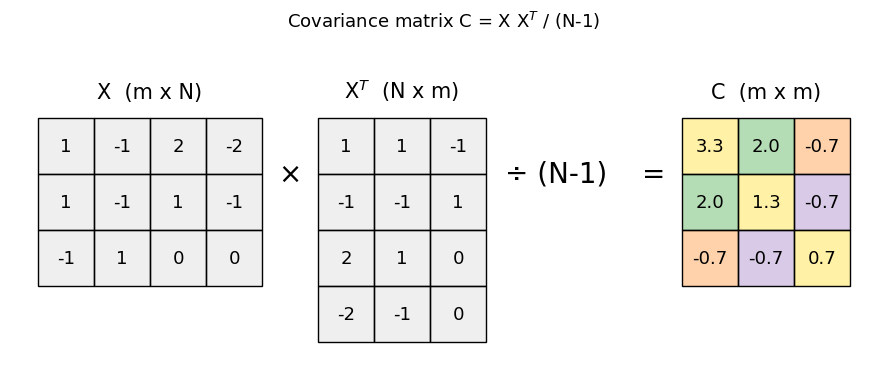

- 노란 칸 (대각선): 각 격자점의 **분산**. 예) $C_{11}$ = $x_1$의 분산
- 나머지 칸: 두 격자점 사이의 **공분산**. 예) $C_{12}$ = $x_1$과 $x_2$의 공분산
- 대각선을 기준으로 접으면 같은 색끼리 같은 값 → $C$는 **대칭행렬** ($C = C^T$)

In [3]:
# 확인 : numpy 의 공분산 함수와 같다
print(C.round(2))
print(np.cov(X).round(2))     # np.cov : 행 = 변수(격자점) 로 보고 공분산 행렬을 구한다

[[ 3.33  2.   -0.67]
 [ 2.    1.33 -0.67]
 [-0.67 -0.67  0.67]]
[[ 3.33  2.   -0.67]
 [ 2.    1.33 -0.67]
 [-0.67 -0.67  0.67]]


**실제 SST에서는?** 오늘 실습 자료는 격자점이 60 × 200 = 12,000개, 시간이 449개이다.
→ $X$는 12,000 × 449, $C$는 **12,000 × 12,000** 이다. 이렇게 큰 계산은 아래 실습에서 `Eof`가 대신 해 준다.

### Eigenvalues and Eigenvectors

$$
C\,e = \lambda\,e
$$

행렬 $C$를 곱하면(linear transformation) 일반적으로 벡터의 방향과 크기가 바뀐다.
슬라이드의 질문: **$C$를 곱해도 방향은 그대로이고, 몇 배만 되는 벡터 $e$가 있을까?** → 그 벡터가 고유벡터 $e$, 그 **배수**가 고유값 $\lambda$이다.

슬라이드 예제: $C = \begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix}$ → $\lambda = 1, 3$, $\;e_{\lambda=1} = \begin{pmatrix} 1 \\ -1 \end{pmatrix}$, $\;e_{\lambda=3} = \begin{pmatrix} 1 \\ 1 \end{pmatrix}$

In [4]:
C = np.array([[2, 1],
              [1, 2]])      # 슬라이드 예제 (공분산 행렬은 대칭)

e_1 = np.array([1, -1])     # e_(λ=1)
e_3 = np.array([1,  1])     # e_(λ=3)
v   = np.array([1,  0])     # 고유벡터가 아닌 벡터 (비교용)

print('C e_(λ=1) =', C @ e_1)   # [ 1 -1] = 1 × e_(λ=1) : 방향 그대로, 배수 1
print('C e_(λ=3) =', C @ e_3)   # [ 3  3] = 3 × e_(λ=3) : 방향 그대로, 배수 3
print('C v       =', C @ v)     # [ 2  1] : 방향이 바뀐다 → 고유벡터가 아니다

C e_(λ=1) = [ 1 -1]
C e_(λ=3) = [3 3]
C v       = [2 1]


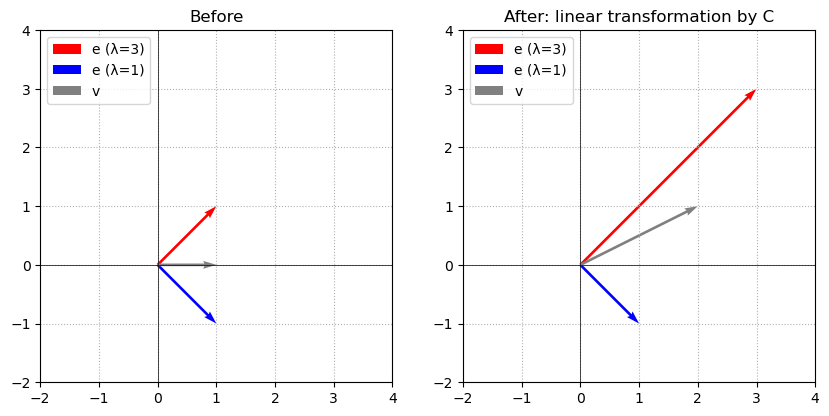

왼쪽: $C$를 곱하기 전, 오른쪽: $C$를 곱한 뒤. 빨강·파랑(고유벡터)은 방향이 그대로이고, 회색 $v$는 방향이 바뀐다.

**그런데 λ = 1, 3 은 어떻게 구했을까?**

$C\,e = \lambda\,e$ 를 한쪽으로 모으면 ($I$: 단위행렬)

$$
(C - \lambda I)\,e = 0
$$

$e = 0$ 이면 당연히 성립하므로, 우리가 찾는 것은 **0이 아닌** $e$ 이다.
만약 $(C - \lambda I)$ 의 역행렬이 있다면 양변에 곱해서 $e = 0$ 이 되어 버린다. 그래서 $(C - \lambda I)$ 는 **역행렬이 없어야** 한다.

역행렬이 없다 ⟺ determinant가 0 이다:

$$
\det(C - \lambda I) = 0
$$

*determinant(행렬식): 행렬이 공간의 면적(또는 부피)을 몇 배로 바꾸는지 나타내는 값이다. 0이면 공간이 선이나 점으로 납작하게 눌려서 원래대로 되돌릴 수 없다. 그래서 역행렬이 없다.*

2×2 행렬의 determinant는 $\det\begin{pmatrix} a & b \\ c & d \end{pmatrix} = ad - bc$ (X자로 곱해서 뺀다). 슬라이드 예제에 넣으면

$$
\det\begin{pmatrix} 2-\lambda & 1 \\ 1 & 2-\lambda \end{pmatrix} = (2-\lambda)^2 - 1 = \lambda^2 - 4\lambda + 3 = (\lambda - 1)(\lambda - 3) = 0
$$

→ $\lambda = 1, 3$. 이 값을 다시 $(C - \lambda I)\,e = 0$ 에 넣으면 고유벡터가 나온다.

- $\lambda = 1$: $\begin{pmatrix} 1 & 1 \\ 1 & 1 \end{pmatrix} e = 0$ → $e_1 + e_2 = 0$ → $e_{\lambda=1} = (1, -1)$
- $\lambda = 3$: $\begin{pmatrix} -1 & 1 \\ 1 & -1 \end{pmatrix} e = 0$ → $e_1 = e_2$ → $e_{\lambda=3} = (1, 1)$

In [5]:
I = np.eye(2)                                  # 단위행렬

for lam_try in [1, 2, 3]:
    d = np.linalg.det(C - lam_try*I)           # det(C - λI)
    print(f'λ = {lam_try} :  det(C - λI) = {d:.1f}')
# λ = 1, 3 에서만 0 → 이 둘이 고유값

print(np.roots([1, -4, 3]))                    # λ^2 - 4λ + 3 = 0 의 해 : [3, 1]

λ = 1 :  det(C - λI) = 0.0
λ = 2 :  det(C - λI) = -1.0
λ = 3 :  det(C - λI) = 0.0
[3. 1.]


**$CE = E\Lambda$ : 고유값 문제의 일반화**

$C\,e = \lambda\,e$ 는 고유벡터 **하나**에 대한 식이다. 고유벡터가 여러 개 있으면, 이 식들을 행렬로 묶어서 **모든 고유벡터에 대해 한 번에** 쓸 수 있다. 이것이 $CE = E\Lambda$ 이다.

슬라이드 예제는 고유벡터가 2개이므로 식도 2개이다.

$$
C\,e_{\lambda=1} = 1 \times e_{\lambda=1}, \qquad C\,e_{\lambda=3} = 3 \times e_{\lambda=3}
$$

- 고유벡터 두 개를 세로로 세워 나란히 붙인 행렬: $E = \begin{pmatrix} 1 & 1 \\ -1 & 1 \end{pmatrix}$ (1열 = $e_{\lambda=1}$, 2열 = $e_{\lambda=3}$)
- 고유값을 대각선에 놓은 행렬: $\Lambda = \begin{pmatrix} 1 & 0 \\ 0 & 3 \end{pmatrix}$

그러면 위의 두 식이 $CE = E\Lambda$ 하나로 쓰인다.
격자점이 $m$개이면 고유벡터도 $m$개이고, $m$개의 식이 똑같이 $CE = E\Lambda$ 하나로 쓰인다 ($E$, $\Lambda$의 크기는 $m \times m$).

그림으로 확인해 보자.

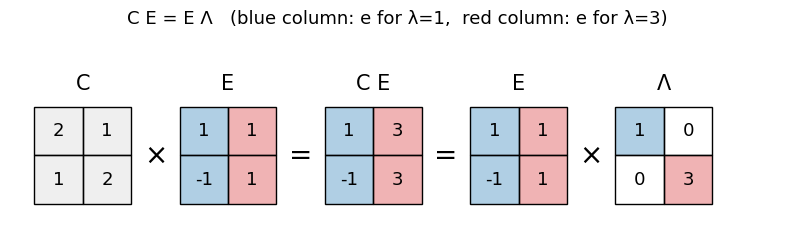

- 파란 열끼리 보면: $C\,e_{\lambda=1} = 1 \times e_{\lambda=1}$
- 빨간 열끼리 보면: $C\,e_{\lambda=3} = 3 \times e_{\lambda=3}$

슬라이드처럼 **$C = E\Lambda E^T$** 로도 쓸 수 있다 (고유벡터 행렬 × 고유값 행렬 × 고유벡터 행렬의 전치). 단, 이 식의 $E$에는 길이가 1이 되도록 정규화한 고유벡터를 사용한다.
`np.linalg.eigh`로 구한 $E$를 넣어서 확인해 보자.

In [6]:
lam, E = np.linalg.eigh(C)        # eigh : 고유값(lam), 고유벡터(E 의 각 열)
print('λ =', lam)                 # [1. 3.]
print('E =\n', E.round(2))        # 1열 : e_(λ=1),  2열 : e_(λ=3)  (0.71 이어도 (1,1), (1,-1) 과 방향이 같다. 부호는 반대로 나올 수 있다)

Lam = np.diag(lam)                # 고유값을 대각선에 놓은 행렬
print('E Λ E^T =\n', (E @ Lam @ E.T).round(2))   # 원래 C 가 다시 나온다

λ = [1. 3.]
E =
 [[-0.71  0.71]
 [ 0.71  0.71]]
E Λ E^T =
 [[2. 1.]
 [1. 2.]]


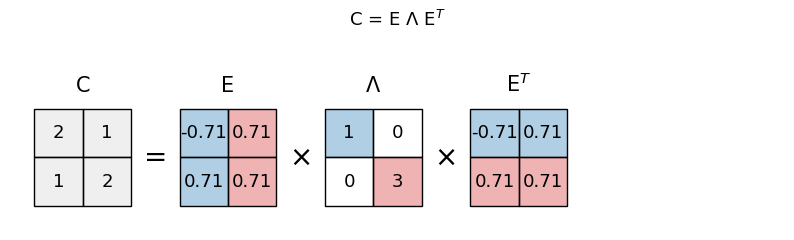

$E^T$에서는 고유벡터가 열이 아니라 **행**으로 놓인다.

### 왜 공분산 행렬일까?

공분산 행렬은 **대칭행렬**이다 ($C^T = C$). $x_1$과 $x_2$의 공분산은 $x_2$와 $x_1$의 공분산과 같기 때문이다.

대칭행렬에는 좋은 성질이 있다.
- 고유값이 **실수**이다 (공분산 행렬이면 0 이상).
- 고유벡터들이 서로 **직교**한다. 예: $(1,1)\cdot(1,-1) = 0$

그래서 공분산 행렬은 위처럼 $C = E\Lambda E^T$ 로 분해할 수 있다. 이 분해를 EOF로 읽으면 다음과 같다.

| | EOF 분석에서 |
|---|---|
| 고유벡터 $e_1$, $e_2$, … | 첫 번째, 두 번째, … **EOF 축** (자료를 설명하는 새로운 축) |
| 고유값 $\lambda_1$, $\lambda_2$, … | 각 축이 설명하는 **분산** |
| $PC_1 = e_1^T X$ | 원래 자료를 첫 번째 축에 **투영**한 값 |

고유값이 가장 큰 고유벡터가 자료의 분산을 가장 많이 설명하는 **EOF1**이 된다.

*강의에서 "고유벡터들이 서로 독립"이라고 할 때, 여기서는 서로 **직교**한다는 뜻이다. 두 변수가 서로 영향을 주지 않는다는 통계적 독립과는 다른 말이다.*

### Finding principal component

앞에서 EOF 분석은 **자료의 분산을 가장 많이 설명하는 새로운 축(고유벡터)을 찾는 과정**이라고 배웠다.

그렇다면 PC는 어떻게 구할까?

**원래 자료를 새롭게 찾은 EOF 축에 투영하면 PC를 얻을 수 있다.**

수학적으로 투영은 각 격자점의 값에 고유벡터의 성분을 곱해 더하는 것으로 나타낼 수 있다.

$$
z=e^TX=e_1x_1+e_2x_2+\cdots
$$

여기서 $e$는 길이가 1인 고유벡터이고, $z$는 투영한 결과인 PC이다.

- **EOF1:** 자료를 투영했을 때 분산이 가장 커지는 방향
- **PC1:** 원래 자료를 EOF1에 투영하여 얻은 값
- **고유값 $\lambda_1$:** PC1의 분산

두 번째 EOF는 첫 번째 EOF와 직교하면서 남은 분산을 가장 많이 설명하는 방향이다.

격자점이 2개뿐인 가상의 자료를 이용하여, **고유벡터에 자료를 투영하면 PC가 만들어지고 그 분산이 고유값과 같아지는지** 확인해 보자.

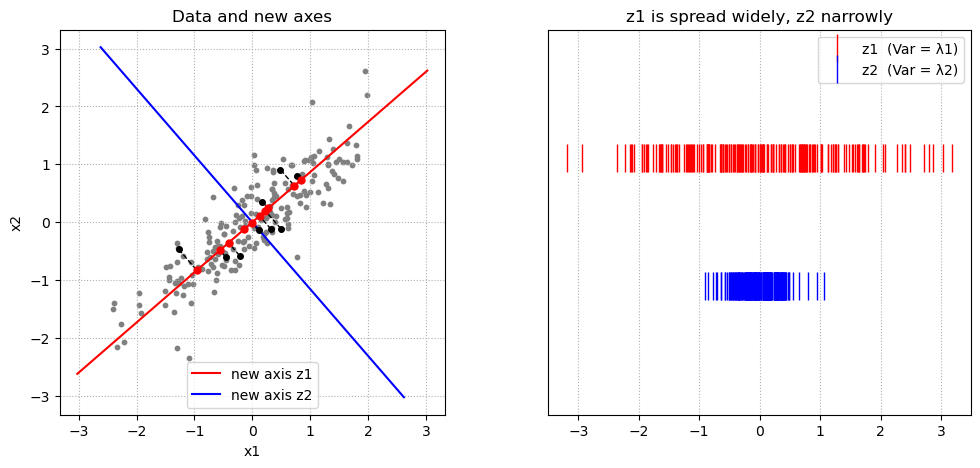

- 왼쪽: 회색 점(자료)과 새로운 축 z1(빨강), z2(파랑). 점선은 자료를 z1 축으로 투영하는 모습이다.
- 오른쪽: 투영한 값 z1은 넓게, z2는 좁게 퍼져 있다 → z1의 분산($\lambda_1$)이 훨씬 크다.

**투영한 값(PC)의 분산 = 고유값**

| | PC의 분산 | 고유값 | 분산 설명률 |
|---|---|---|---|
| PC1 (z1) | 1.55 | $\lambda_1$ = 1.55 | 93.9 % |
| PC2 (z2) | 0.10 | $\lambda_2$ = 0.10 | 6.1 % |

분산 설명률은 $\lambda_i / (\lambda_1 + \lambda_2)$ 이다. 이 가상의 자료에서는 EOF1 하나가 전체 변동의 약 94 %를 설명한다.

**실제 기후자료에서는?**

- **EOF 공간 패턴:** 자료의 주요 변동을 나타내는 새로운 축으로, *어디에서 어떤 변동이 나타나는지* 보여 준다.
- **PC 시계열:** 각 시점의 자료를 EOF 축에 투영하여 얻은 값으로, *그 변동이 시간에 따라 어떻게 나타나는지* 보여 준다.
- **분산 설명률:** 각 EOF 모드가 *전체 변동의 몇 %를 설명하는지* 나타낸다.

아래 SST 실습에서는 공간 패턴을 보기 쉽게 **PC와 각 격자점의 SST 편차 사이의 상관계수**를 지도로 나타낸다 (`eofsAsCorrelation`). 이는 EOF 고유벡터 자체와는 다르지만, 주요 변동의 공간적 특징을 파악하는 데 유용하다.

## ★ Practice: 열대 태평양 SST의 EOF 분석

**분석 흐름:** ① SST에서 월별 기후값을 빼 편차 만들기 → ② EOF 분석 → ③ 상관계수 패턴·PC·분산 설명률 시각화

**생각해 보기:** 왜 SST 원자료가 아니라 계절 주기를 제거한 *anomaly*로 분석할까?

### 1. Prepare anomaly data

**1982년 1월 ~ 2019년 5월**의 월별 SST를 쓴다.

1982~2018년의 **달별 평균**(1월 평균, 2월 평균, …)을 기후값으로 구하고, 각 달의 SST에서 빼서 anomaly를 만든다. 이렇게 하면 매년 반복되는 계절 변화가 빠진다.

**왜 2019년 5월까지일까?** 자료를 2023년까지 늘리면 EOF2와 EOF3의 순서가 바뀐다 (두 모드의 분산 설명률이 비슷하기 때문이다). 슬라이드와 같은 결과를 보기 위해 기간을 잘랐다.

In [7]:
# ★ 핵심 코드
#####################  EOF analysis on Tropical SST  ######################
##################### Prepare Anomaly data #####################
dset = xr.open_dataset('../data/sst.mnmean.nc')
sst = dset['sst'].sel(time=slice('1982-01', '2019-05'))   # 슬라이드 결과와 같은 기간

#-------- Select EOF analysis area --------
area = sst.where((sst.lat<30) & (sst.lat>-30) & (sst.lon>100) & (sst.lon<300), drop=True)

#---------- Calculate climatology ----------
clim = area.sel(time=slice('1982-01','2018-12')).groupby('time.month').mean(dim='time', keep_attrs=True)

#---------- Calculate anomalies ------------
anomt = area.groupby('time.month') - clim
anom = anomt.drop_vars('month')    # to remove one of two time coordinates: time, month
print(anom.shape)                  # (time, lat, lon)

(449, 60, 200)


### 2. Perform EOF analysis

앞서 배운 EOF 분석은 공분산 행렬의 고유값과 고유벡터를 구하여 자료의 주요 변동 패턴을 찾는 방법이다.

Python에서는 `Eof`를 이용하여 이 과정을 수행할 수 있다.

**① 위도 가중치 설정**

위도에 따라 격자 면적이 다르므로, 이를 고려하기 위해 위도 가중치를 적용한다.

- `coslat`: 위도별 상대적인 격자 면적을 계산한다.
- `wgts`: 공분산 계산에 면적 가중치가 반영되도록 제곱근을 사용한다.
- `np.newaxis`: 위도별 가중치를 모든 경도에 적용할 수 있도록 배열의 차원을 조정한다.

**② EOF 분석 수행**

```python
solver = Eof(anom, weights=wgts)
```

`Eof`는 SST 편차 자료(`anom`)를 이용하여 EOF 분석을 수행한다.

**③ 분석 결과 추출**

| 함수 | 의미 |
|---|---|
| `eofsAsCorrelation(neofs=3)` | 각 PC와 격자점 자료 사이의 상관계수로 표현한 공간 패턴 |
| `pcs(npcs=3, pcscaling=1)` | 각 모드의 시간적 변화(표준화된 PC) |
| `varianceFraction()` | 각 모드가 설명하는 전체 분산의 비율 |
| `northTest(vfscaled=True)` | 분산 설명률의 표본오차 추정 |

**결과를 해석할 때 기억할 점**

- **EOF 공간 패턴**은 자료의 주요 변동을 나타내는 새로운 축으로, *어디에서 어떤 변동이 나타나는지*를 보여 준다.
- **PC 시계열**은 각 시점의 자료를 해당 EOF 축에 투영하여 얻은 값으로, *그 변동이 시간에 따라 어떻게 나타나는지*를 보여 준다.
- **분산 설명률**(explained variance ratio)은 *각 패턴이 전체 변동의 몇 %를 설명하는지*를 나타낸다.
- EOF와 PC의 부호는 동시에 반대로 바뀔 수 있으므로, 부호 자체보다 공간 패턴과 시간적 변화를 함께 해석하는 것이 중요하다.

즉, **EOF는 공간 패턴, PC는 시간 변화, 분산 설명률은 그 패턴의 비중**이라고 이해하면 된다.

In [8]:
# ★ 핵심 코드
##################### Perform EOF Analysis #######################
# --- square-root of cosine of latitude weights
coslat = np.cos(np.deg2rad(anom.coords['lat'].values))
wgts = np.sqrt(coslat)[:, np.newaxis]           # 위도 가중치

# --- EOF solver
solver = Eof(anom, weights=wgts)

# --- EOF results
eofs = solver.eofsAsCorrelation(neofs=3)        # EOF 지도      (mode, lat, lon)
pcs = solver.pcs(npcs=3, pcscaling=1)           # PC 시계열     (time, mode)
variance_fractions = solver.varianceFraction()  # 분산 설명률
north_test = solver.northTest(vfscaled=True)    # 분산 설명률의 오차 범위

print((variance_fractions[0:3]*100).values.round(1))   # EOF1, 2, 3 의 분산 설명률 (%)

[34.1  9.   7.5]


In [9]:
# 확인 : 결과의 모양
print('wgts :', wgts.shape)                            # (위도, 1)        : 위도마다 무게 하나
print('eofs :', eofs.shape)                            # (모드, 위도, 경도) : 모드 3개의 지도
print('pcs  :', pcs.shape)                             # (시간, 모드)      : 모드 3개의 시계열

wgts : (60, 1)
eofs : (3, 60, 200)
pcs  : (449, 3)


### 3. Plotting

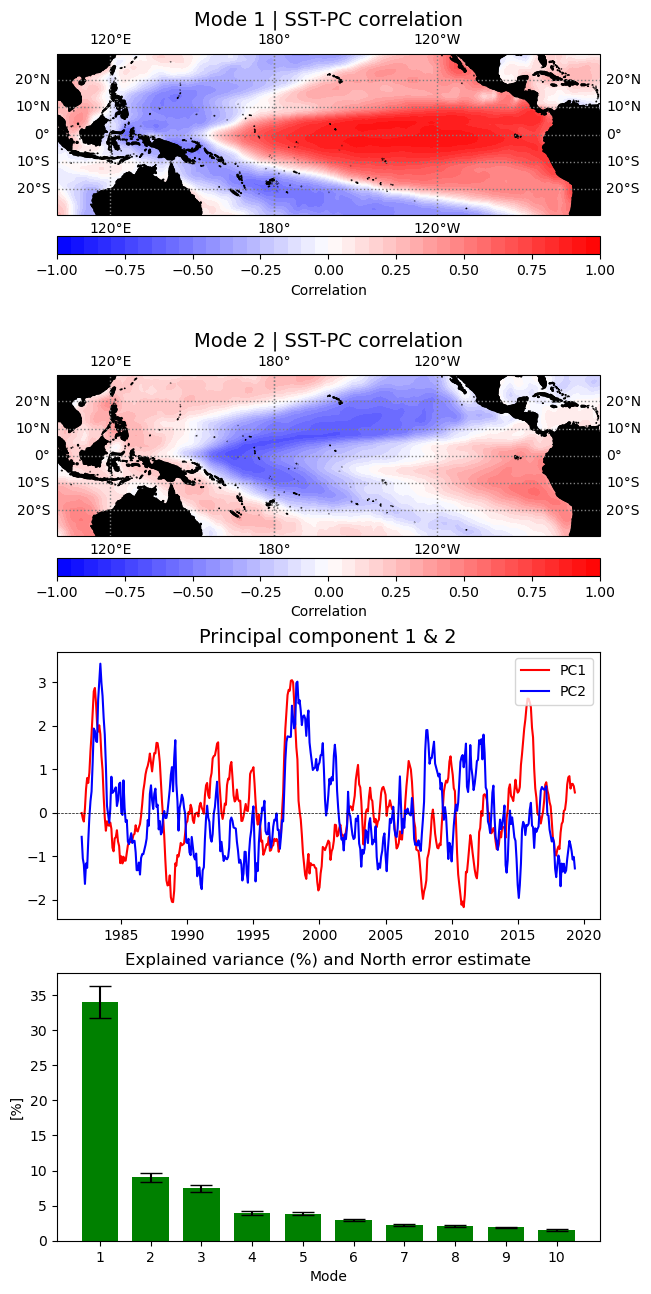

In [10]:
# ★ 핵심 코드
##########################  Plotting  ############################
fig = plt.figure(figsize=(7,16))

lons = eofs["lon"]
lats = eofs["lat"]

# Sub-Figure 1 - first EOF mode
clevs=np.arange(-1, 1.05, 0.05)
ax1 = plt.subplot(411, projection = ccrs.PlateCarree(180))
a = ax1.contourf(lons, lats, eofs[0, :, :], levels=clevs, cmap='bwr', transform=ccrs.PlateCarree())
ax1.set_title('Mode 1 | SST-PC correlation', fontsize=14)
ax1.coastlines()
ax1.gridlines(draw_labels=True, linewidth=1, linestyle=':', color='gray')
ax1.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '50m', edgecolor='face', facecolor='black'))
plt.colorbar(a, ax=ax1, orientation = "horizontal", pad=0.08, aspect= 30, label='Correlation')

# Sub-Figure 2 - second EOF mode
clevs=np.arange(-1, 1.05, 0.05)
ax2 = plt.subplot(412, projection = ccrs.PlateCarree(180))
b = ax2.contourf(lons, lats, eofs[1, :, :], levels=clevs, cmap='bwr', transform=ccrs.PlateCarree())
ax2.set_title('Mode 2 | SST-PC correlation', fontsize=14)
ax2.coastlines()
ax2.gridlines(draw_labels=True, linewidth=1, linestyle=':', color='gray')
ax2.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '50m', edgecolor='face', facecolor='black'))
plt.colorbar(b, ax=ax2, orientation = "horizontal", pad=0.08, aspect= 30, label='Correlation')

# Sub-Figure 3 - principal components
ax3 = plt.subplot(413)
ax3.plot(pcs['time'], pcs[:, 0], color='red', label='PC1')
ax3.plot(pcs['time'], pcs[:, 1], color='blue', label='PC2')
ax3.set_title('Principal component 1 & 2', fontsize=14)
ax3.axhline(0,color='k',linewidth=0.5,linestyle='dashed')
plt.legend()

# Sub-Figure 4 - percentage variance
ax4 = plt.subplot(414)
ax4.bar(list(range(1,11)), variance_fractions[0:10]*100, yerr=north_test[0:10]*100, color='g', ecolor='black', width = 0.72, capsize=8)
ax4.set_title('Explained variance (%) and North error estimate', fontsize=12)
ax4.set_xlabel('Mode')
ax4.set_ylabel('[%]')
ax4.set_xticks(np.arange(1, 11))

plt.show()

## (참고) 더 알아보기

★ 핵심 코드(1~3)의 결과를 이해하는 데 도움이 되는 내용이다. 마지막 lead/lag correlation은 **그림만** 실었다. 과제 2번(correlogram)에서 이 그림을 직접 그려 보자.

### 그림 읽는 법

- **Mode 1 지도**: 적도 동태평양에서 함께 나타나는 SST 변동을 살펴보자. 엘니뇨·라니냐와 관련된 패턴인지 생각해 보자.
- **PC1**: 1982/83, 1997/98, 2015/16년 부근의 변화를 살펴보자. PC의 양·음 부호는 지도와 함께 해석한다.
- **분산 설명률**: 첫 번째 모드가 전체 변동의 약 1/3을 설명한다.
- **색이 슬라이드와 반대로 나와도 괜찮다.** 지도와 PC의 부호를 함께 뒤집으면 같은 결과이기 때문이다 (−1 × −1 = 1).
- **오차막대**: North test의 표본오차 추정치이다. 가까운 모드의 고유값이 구별되는지 판단할 때 참고한다. 다만 월별 자료의 자기상관 때문에 실제 불확실성은 더 클 수 있다.

**주의:** EOF는 통계적으로 나눈 패턴이다. 모드 하나가 꼭 물리 현상 하나와 짝지어지는 것은 아니다.

### 원래 SST와 anomaly 비교

anomaly를 만들면 매년 반복되는 계절 변화가 빠지고 무엇이 남는지 한 격자점에서 확인해 보자.

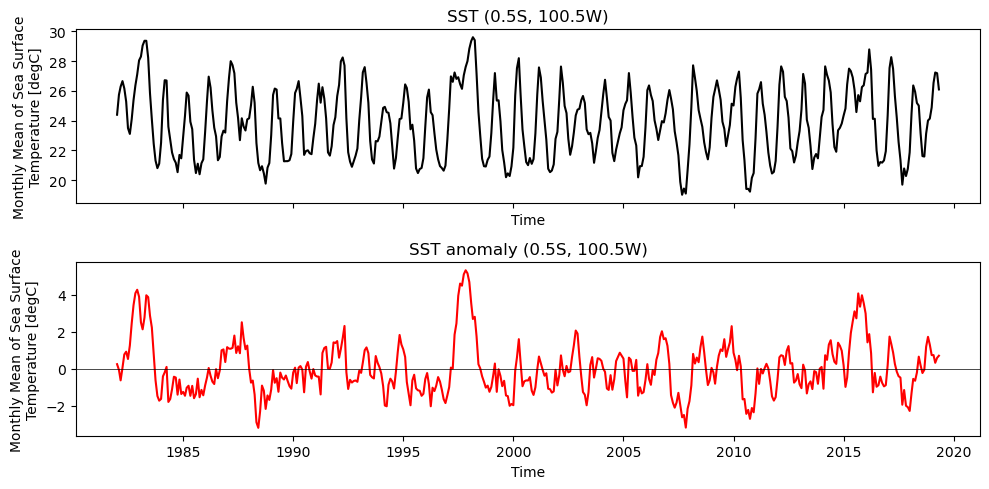

In [11]:
# 한 격자점(0.5S, 100.5W)에서 원래 SST 와 anomaly 비교
pt = dict(lat=-0.5, lon=259.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
area.sel(**pt).plot(ax=axes[0], color='k')
axes[0].set_title('SST (0.5S, 100.5W)')              # 매년 반복되는 계절 변화가 크다
anom.sel(**pt).plot(ax=axes[1], color='r')
axes[1].axhline(0, color='k', lw=0.5)
axes[1].set_title('SST anomaly (0.5S, 100.5W)')      # 계절 변화가 빠지고 엘니뇨/라니냐가 남는다
plt.tight_layout(); plt.show()

### Reconstruction: 앞의 두 모드로 자료 복원하기

앞에서 **PC는 각 시점의 자료를 EOF 축에 투영해서 얻은 값**이라고 했다 (자료 → PC).
이번에는 **거꾸로** 간다. 각 시점의 PC 값만큼 EOF 공간 패턴을 곱해서 더하면 자료로 되돌아온다 (PC → 자료).

$$
\text{그 달의 anomaly 지도} = \text{PC1(그 달)} \times \text{EOF1 공간 패턴} + \text{PC2(그 달)} \times \text{EOF2 공간 패턴} + \cdots
$$

Recap의 가짜 자료 그림에서, 회색 점을 z1 축 위로 내린 **빨간 점**이 바로 이것이다. 모드 1개만으로 복원한 자료이다.

- 모든 모드를 더하면 원래 자료와 똑같아진다.
- 앞의 두 모드만 더하면 분산 설명률이 큰 패턴만 남는다. 그래서 원래 자료의 큰 특징만 담긴 **비슷한** 지도가 된다.

`solver.reconstructedField(2)`가 앞의 두 모드로 이 계산을 해 준다.

*주의:* 위 그림의 `eofs`(상관계수 지도)와 `pcs`(표준화된 PC)는 보기 좋게 크기를 바꾼 값이다. 그래서 둘을 직접 곱하면 원래 °C 크기가 나오지 않는다. 복원할 때는 `reconstructedField`를 쓰자.

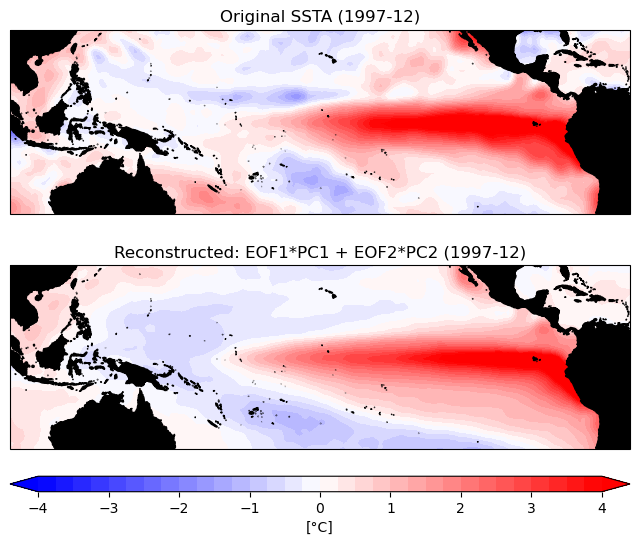

In [12]:
rec = solver.reconstructedField(2)       # EOF1, EOF2 로 복원한 SST anomaly (time, lat, lon) [°C]
t97 = '1997-12-01'                       # 강한 엘니뇨 시기

clevs = np.arange(-4, 4.1, 0.25)
fig = plt.figure(figsize=(8, 7))
for k, (data, title) in enumerate([(anom, 'Original SSTA (1997-12)'),
                                   (rec,  'Reconstructed: EOF1*PC1 + EOF2*PC2 (1997-12)')]):
    ax = plt.subplot(2, 1, k+1, projection=ccrs.PlateCarree(180))
    c = ax.contourf(lons, lats, data.sel(time=t97), levels=clevs, cmap='bwr',
                    extend='both', transform=ccrs.PlateCarree())
    ax.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '50m', edgecolor='face', facecolor='black'))
    ax.set_title(title)
plt.colorbar(c, ax=fig.axes, orientation='horizontal', pad=0.05, aspect=40, label='[°C]')
plt.show()

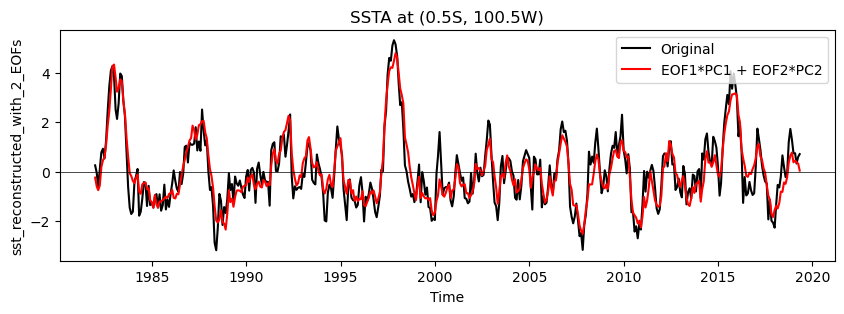

In [13]:
# 한 격자점에서 시계열로 비교
plt.figure(figsize=(10, 3))
anom.sel(**pt).plot(color='k', label='Original')
rec.sel(**pt).plot(color='r', label='EOF1*PC1 + EOF2*PC2')
plt.axhline(0, color='k', lw=0.5); plt.legend(); plt.title('SSTA at (0.5S, 100.5W)')
plt.show()
# 두 모드가 어떤 변동을 재현하고, 어떤 변동을 놓치는지 비교한다

### PC1과 PC2의 lead/lag correlation

Practice 8의 correlogram은 **한 시계열을 자기 자신과** 비교했다. 이번에는 **서로 다른 두 PC**를 몇 달 밀어서 비교한다.

- 가로축 0: 같은 시점끼리 비교하면 상관이 0이다 (EOF 분석이 그렇게 만든다)
- 가로축 음수 (왼쪽): PC2가 먼저 나타난다 → **PC2 lead**
- 가로축 양수 (오른쪽): PC1이 먼저 나타난다 → **PC1 lead**

**예: lag = −12** 이면 PC2와 **12개월 뒤의** PC1을 짝지어 상관을 구한다.

| PC2 | PC1 |
|---|---|
| 1982년 1월 | 1983년 1월 |
| 1982년 2월 | 1983년 2월 |
| … | … |
| 2018년 5월 | 2019년 5월 |

이 상관이 크면, PC2가 나타나고 약 1년 뒤에 PC1이 나타나는 경향이 있다는 뜻이다.

**초록 점**: p-value < 0.05인 lag. 다만 월별 자료는 이웃한 달끼리 비슷해서 보통의 p-value로는 유의하다고 너무 쉽게 나온다. 초록 점은 참고로만 보자.

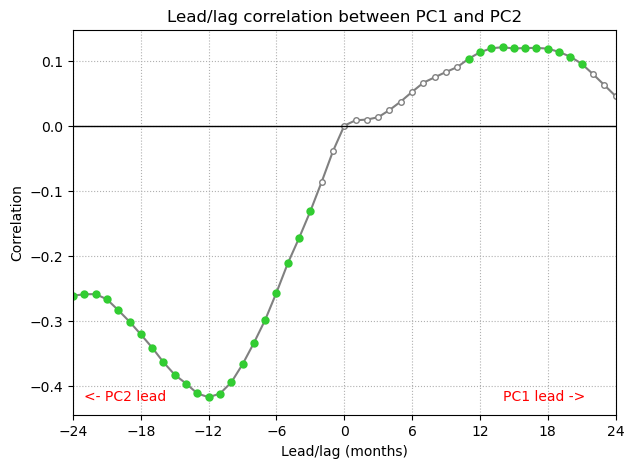

**해석**

- 가로축 0에서 상관이 0이다. 같은 시점끼리는 상관이 없다.
- 가로축 약 −12에서 상관이 크게 나타난다면, **PC2의 변화가 약 1년 뒤 PC1의 변화와 관련되는 경향**으로 해석할 수 있다. 실제 상관의 크기와 부호는 그래프에서 확인하자.
- 이런 시차상관은 두 모드가 시간적으로 연결되어 있을 가능성을 보여 준다. 다만 이것만으로 두 모드가 하나의 현상(ENSO)의 서로 다른 단계라고 확정하거나 원인과 결과를 말할 수는 없다.

## Homework

1. Perform EOF analysis for winter (DJF) North Pacific (120°E–240°E; 20°N–60°N) SLP (Sea Level Pressure) and then plot EOF pattern 1 and 2, PC time series 1 and 2, and eigenvalues.
2. Plot the correlogram (i.e., lagged correlation coefficient) between PC time series 1 and 2.